<a href="https://colab.research.google.com/github/MBA009/membership_inference_attack/blob/main/%5BMissing_In_Action%5D_MIA_phase2_3_(FINAL).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Initialize Workbook
Run the code in this section on opening the notebook, prior to running **any** other section!

In [ ]:
%cd /content
!git clone https://github.com/2020pyfcrawl/18734-17731_Project_Phase2_3.git
%cd /content/18734-17731_Project_Phase2_3

/content
Cloning into '18734-17731_Project_Phase2_3'...
remote: Enumerating objects: 70, done.
remote: Counting objects: 100% (32/32), done.
remote: Compressing objects: 100% (17/17), done.
remote: Total 70 (delta 18), reused 19 (delta 15), pack-reused 38 (from 1)
Receiving objects: 100% (70/70), 55.70 MiB | 22.20 MiB/s, done.
Resolving deltas: 100% (24/24), done.
/content/18734-17731_Project_Phase2_3


In [ ]:
# Install the required libraries. Don't run this on Colab---it has them already.
%pip install -r requirements.txt

## Import Necessary Packages

In [ ]:
import argparse
from datasets import Dataset, load_from_disk
import json
import math
import matplotlib.pyplot as plt
import numpy as np
import os
from pathlib import Path
from sklearn.metrics import roc_auc_score, roc_curve, auc as _auc
import torch
from torch.utils.data import DataLoader
from transformers import AutoTokenizer, AutoModelForCausalLM
from typing import Mapping, MutableMapping, Sequence, Any
import zipfile

os.environ.setdefault("TRANSFORMERS_NO_TORCHVISION", "1")
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"

## Define Utility Functions

In [ ]:
def tokenize_dataset(
    dataset: Sequence[Mapping[str, Any]],
    tokenizer: Any,
    max_length: int,
) -> Sequence[MutableMapping[str, Any]]:
    """Tokenizes a dataset using the provided tokenizer and constraints.

    Args:
        dataset: The dataset to tokenize (e.g., a Hugging Face Dataset object).
        tokenizer: The tokenizer object (e.g., a Hugging Face AutoTokenizer).
        max_length: The maximum sequence length for truncation and padding.

    Returns:
        The tokenized dataset with 'input_ids', 'attention_mask', and 'labels'
        set to 'torch' format.
    """
    dataset = dataset.filter(
        lambda example: example.get("text") and example["text"].strip()
    )

    def _map(examples: Mapping[str, Sequence[Any]]) -> MutableMapping[str, Sequence[Any]]:
        """Maps the tokenizer over a batch of examples."""
        outputs = tokenizer(
            examples["text"],
            truncation=True,
            padding="longest",
            max_length=max_length,
            return_attention_mask=True,
        )
        outputs["labels"] = outputs["input_ids"][:]
        return outputs

    dataset = dataset.map(_map, batched=True, remove_columns=["text"])

    dataset.set_format(type="torch", columns=["input_ids", "attention_mask", "labels"])
    return dataset

def read_json(path: Path) -> Mapping[str, Any]:
    """Reads a JSON file from the given path.

    Args:
        path: The path to the JSON file.

    Returns:
        The loaded JSON content as a dictionary (or other mapping).
    """
    with path.open("r", encoding="utf-8") as file_handle:
        return json.load(file_handle)

## Set Global Variables

In [ ]:
# Hyperparameters
BATCH_SIZE = 50
BLOCK_SIZE = 512 # Maximum length: 512
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
PHASE = "final" # Options: "train", "val", "final"

# Path variables
ROOT = Path("/content/18734-17731_Project_Phase2_3")

DATA_DIR = ROOT / "data" / PHASE
TARGET_MODEL_DIR = ROOT / "models" / PHASE / "gpt2_3_lora32_adamw_b8_lr2"
SHADOW_MODELS_ROOT = ROOT / "models" / "shadow"

SHADOW_DATA_ROOT = ROOT / "data" / "shadow"
LABEL_PATH = DATA_DIR / "test_label.json"
PREDICTION_PATH = DATA_DIR / "prediction.csv"
TEST_PATH = DATA_DIR / "test.json"

## Preprocess Data

In [ ]:
# Load test data.
test_items = read_json(TEST_PATH)
test_dataset = Dataset.from_dict({"text": test_items})

# Initialize tokenizer.
tokenizer = AutoTokenizer.from_pretrained(TARGET_MODEL_DIR, use_fast=True)

# Configure tokenizer padding.
if tokenizer.pad_token is None:
    tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

# Tokenize the test data using a previously defined function.
test_dataset = tokenize_dataset(test_dataset, tokenizer, BLOCK_SIZE)

# Create DataLoader.
dataloader_test = DataLoader(test_dataset, batch_size=BATCH_SIZE)

# To load the model:
# model = (
#     AutoModelForCausalLM.from_pretrained(TARGET_MODEL_DIR, torch_dtype="auto")
#     .to(DEVICE)
# )

Filter:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

# A) Generate Shadow Model(s)

In [ ]:
# Set this before beginning!
SEEDS = [104, 105, 106, 107]

# ==============================================================================
# 0. IMPORTS AND SETUP
# ==============================================================================

import json
import os
import sys
import random
from pathlib import Path
from typing import Mapping, Sequence, Any, List, Dict
import zipfile

# Set environment variable early
os.environ.setdefault("TRANSFORMERS_NO_TORCHVISION", "1")

# Third-party imports
import torch
from datasets import load_dataset, Dataset
from peft import LoraConfig, PeftModel, get_peft_model
from transformers import (
    AutoModelForCausalLM,
    AutoTokenizer,
    DataCollatorForLanguageModeling,
    Trainer,
    TrainingArguments,
)


# ==============================================================================
# 1. CONFIGURATION CONSTANTS
# ==============================================================================

# File system configuration
INPUT_DIR = ROOT / "data" / "shadow"

# Data configuration
TRAIN_PER_SRC = 10_000
MIN_TOKENS = 25

# Training configuration
MODEL_NAME = "gpt2"
NUM_EPOCHS = 3
PER_DEVICE_BATCH_SIZE = 8
GRADIENT_ACCUMULATION_STEPS = 1
LEARNING_RATE = 2e-4
WEIGHT_DECAY = 0.01
USE_GRADIENT_CHECKPOINTING = False

# LoRA configuration
USE_LORA = True
LORA_R = 32
LORA_ALPHA = 64
LORA_DROPOUT = 0.05
TARGET_MODULES_STR = ""  # e.g., "c_attn,c_fc,c_proj"
MERGE_LORA = False


# ==============================================================================
# 2. HELPER FUNCTIONS (Alphabetized)
# ==============================================================================

def basic_clean(ds: Dataset) -> Dataset:
    """Filters empty/non-string samples and strips excessive whitespace."""
    ds = ds.filter(lambda ex: isinstance(ex.get("text", None), str) and len(ex["text"].strip()) > 0)
    def _strip_map(ex): return {"text": " ".join(ex["text"].split())}
    return ds.map(_strip_map, batched=False)

def dump_json(path: Path, obj):
    """Saves a Python object to a JSON file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    with path.open("w", encoding="utf-8") as f:
        json.dump(obj, f, ensure_ascii=False, indent=2)

def ensure_text_column(ds: Dataset, src: str) -> Dataset:
    """Ensures the dataset has only a 'text' column for training."""
    if src == "wikitext103":
        assert "text" in ds.column_names
        return ds.remove_columns([c for c in ds.column_names if c != "text"])
    raise ValueError(src)

def filter_by_tokens(ds: Dataset, tokenizer: AutoTokenizer, min_tokens: int) -> Dataset:
    """Filters samples based on minimum token length."""
    def _len_map(batch):
        # Do not add special tokens when calculating length
        enc = tokenizer(batch["text"], add_special_tokens=False)
        return {"_tok_len": [len(ids) for ids in enc["input_ids"]]}
    ds = ds.map(_len_map, batched=True)
    ds = ds.filter(lambda ex: ex["_tok_len"] >= min_tokens)
    return ds.remove_columns(["_tok_len"])

def filter_non_empty_text(example: Mapping[str, Any]) -> bool:
    """Filters out samples where the 'text' field is empty or whitespace-only."""
    text = example.get("text", "")
    return text is not None and len(text.strip()) > 0

def infer_lora_targets(model: Any, fallback_gpt2: bool = True) -> List[str]:
    """Infers LoRA target modules based on the model type."""
    model_type = getattr(getattr(model, "config", None), "model_type", "") or model.__class__.__name__.lower()

    if "gpt2" in model_type and fallback_gpt2:
        return ["c_attn", "c_fc", "c_proj"]

    # Fallback for LLaMA/Mistral-like architectures (common PEFT targets)
    return ["q_proj", "k_proj", "v_proj", "o_proj", "gate_proj", "up_proj", "down_proj"]

def read_json(path: Path) -> Sequence[Mapping[str, Any]]:
    """Reads a JSON file from the given path."""
    with path.open("r", encoding="utf-8") as file_handle:
        return json.load(file_handle)

def sample_n(ds: Dataset, n: int, seed: int) -> Dataset:
    """Randomly samples N items from the dataset."""
    n_samples = min(n, len(ds))
    # Note: `ds.select(range(len(ds))).shuffle(seed=seed).select(range(n_samples))` is cleaner,
    # but using explicit list shuffle for compatibility with original logic.
    idx = list(range(len(ds)))
    random.Random(seed).shuffle(idx)
    take = sorted(idx[:n_samples])
    return ds.select(take)

def set_seed_all(seed: int):
    """Sets the seed for reproducibility across random, numpy, and torch."""
    import numpy as np
    random.seed(seed)
    np.random.seed(seed)
    try:
        torch.manual_seed(seed)
        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(seed)
    except Exception:
        pass

def tokenize_map(examples: Mapping[str, Sequence[Any]], tokenizer: AutoTokenizer, block_size: int) -> Dict[str, Sequence[Any]]:
    """Tokenizes a batch of examples, ensuring non-empty texts are handled."""
    # Ensure empty strings are replaced with the EOS token to prevent tokenizer errors
    texts = [
        (text if text and text.strip() else tokenizer.eos_token)
        for text in examples["text"]
    ]

    return tokenizer(
        texts,
        padding="max_length",
        truncation=True,
        max_length=block_size,
        return_attention_mask=True,
    )

def zip_directory(src_dir: Path, output_zip_path: Path):
    """Creates a zip archive of the contents of a directory.

    Args:
        src_dir: The directory to archive.
        output_zip_path: The path to save the resulting zip file.
    """
    print(f"Creating archive for model in {src_dir}...")
    with zipfile.ZipFile(output_zip_path, 'w', zipfile.ZIP_DEFLATED) as zipf:
        # Walk through the source directory
        for root, _, files in os.walk(src_dir):
            root_path = Path(root)
            # Add files to the zip, preserving directory structure relative to src_dir
            for file in files:
                file_path = root_path / file
                # Create the arcname (name inside the zip) by calculating the relative path
                arcname = file_path.relative_to(src_dir.parent)
                zipf.write(file_path, arcname)
    print(f"[OK] Model archive created at: {output_zip_path.resolve()}")

# ==============================================================================
# 3. DATA PREPARATION LOGIC
# ==============================================================================
for SEED in SEEDS:
    print(f"\n=== Beginning Seed {SEED} ===")
    INPUT_NAME = f"train_{SEED}.json"
    OUTPUT_DIR = ROOT / "models" / "shadow" / f"shadow_model_{SEED}"
    set_seed_all(SEED)
    INPUT_DIR.mkdir(parents=True, exist_ok=True)

    # Initialize Tokenizer for filtering/data prep
    tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
    if tokenizer.pad_token is None:
        tokenizer.pad_token = tokenizer.eos_token

    print("--- Data Preparation ---")
    # ---------- Load & filter (WikiText-103-raw-v1) ----------
    wiki_raw = load_dataset("Salesforce/wikitext", "wikitext-103-raw-v1", split="train")
    wiki = ensure_text_column(wiki_raw, "wikitext103")
    wiki = basic_clean(wiki)
    wiki = filter_by_tokens(wiki, tokenizer, MIN_TOKENS)

    # train set: samples from the filtered wiki dataset
    wiki_train = sample_n(wiki, TRAIN_PER_SRC, SEED + 1)

    # Convert to list of dictionaries for JSON dump
    train_json = [{"text": ex["text"]} for ex in wiki_train]

    # Dump data to file
    dump_json(INPUT_DIR / INPUT_NAME, train_json)

    print(f"[OK] Training data ({len(train_json)} samples) saved to {INPUT_DIR / INPUT_NAME}")

# ==============================================================================
# 4. TRAINING LOGIC
# ==============================================================================

    print("\n--- Starting Fine-Tuning Setup ---")

    # Convert list of training examples to a Hugging Face Dataset
    dataset_raw = Dataset.from_list(train_json)

    # Filter empty samples (re-filtering is safe)
    dataset_raw = dataset_raw.filter(filter_non_empty_text)

    # Tokenizer is already initialized and configured from Section 3 (using `tokenizer`)

    # Tokenize the dataset
    dataset_tokenized = dataset_raw.map(
        lambda ex: tokenize_map(ex, tokenizer, BLOCK_SIZE),
        batched=True,
        remove_columns=dataset_raw.column_names,
    )

    # Data collator for causal language modeling (CLM)
    collator = DataCollatorForLanguageModeling(tokenizer=tokenizer, mlm=False)

    print(f"Total tokenized samples: {len(dataset_tokenized)}")
    if len(dataset_tokenized) > 0:
        min_len = min(len(x) for x in dataset_tokenized["input_ids"])
        max_len = max(len(x) for x in dataset_tokenized["input_ids"])
        print(f"Min/Max token length: {min_len}/{max_len}")
    print(f"Target device: {DEVICE}")

    # --- Model Loading ---
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME)
    model.resize_token_embeddings(len(tokenizer))
    model.to(DEVICE)

    # --- Optional LoRA Configuration ---
    if USE_LORA:
        # Determine target modules
        if TARGET_MODULES_STR.strip():
            target_modules = [m.strip() for m in TARGET_MODULES_STR.split(",") if m.strip()]
        else:
            target_modules = infer_lora_targets(model, fallback_gpt2=True)

        lora_config = LoraConfig(
            r=LORA_R,
            lora_alpha=LORA_ALPHA,
            lora_dropout=LORA_DROPOUT,
            target_modules=target_modules,
            bias="none",
            task_type="CAUSAL_LM",
        )

        model = get_peft_model(model, lora_config)

        if USE_GRADIENT_CHECKPOINTING:
            model.enable_input_require_grads()

        try:
            model.print_trainable_parameters()
        except AttributeError:
            print("PEFT model loaded. Trainable parameters summary not available.")


    # --- Training Arguments and Trainer ---
    training_args = TrainingArguments(
        output_dir=str(OUTPUT_DIR),
        num_train_epochs=NUM_EPOCHS,
        per_device_train_batch_size=PER_DEVICE_BATCH_SIZE,
        gradient_accumulation_steps=GRADIENT_ACCUMULATION_STEPS,
        learning_rate=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY,
        lr_scheduler_type="cosine",
        warmup_ratio=0.03,
        logging_steps=250,
        save_strategy="no",
        seed=SEED,
        fp16=True,
        bf16=False,
        no_cuda=False,
        report_to="none",
        gradient_checkpointing=USE_GRADIENT_CHECKPOINTING,
        optim="adamw_torch",
    )

    trainer = Trainer(
        model=model,
        args=training_args,
        train_dataset=dataset_tokenized,
        tokenizer=tokenizer,
        data_collator=collator,
    )

    print("\nStarting training...")
    trainer.train()
    print("Training complete.")

    # --- Save Model ---
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

    if USE_LORA and MERGE_LORA:
        if isinstance(model, PeftModel):
            base_model = model.merge_and_unload()
        else:
            base_model = model

        base_model.save_pretrained(OUTPUT_DIR)
        tokenizer.save_pretrained(OUTPUT_DIR)
        print(f"[OK] Merged LoRA and saved full model to {OUTPUT_DIR}")
    else:
        model.save_pretrained(OUTPUT_DIR)
        tokenizer.save_pretrained(OUTPUT_DIR)
        print(f"[OK] Model (with LoRA adapters if enabled) saved to {OUTPUT_DIR}")

    # --- Archive Model ---
    ZIP_PATH = OUTPUT_DIR.with_suffix(".zip")
    zip_directory(OUTPUT_DIR, ZIP_PATH)


=== Beginning Seed 104 ===


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

...

Total tokenized samples: 10000
Min/Max token length: 512/512
Target device: cuda


/usr/local/lib/python3.12/dist-packages/peft/tuners/lora/layer.py:2285: UserWarning: fan_in_fan_out is set to False but the target module is `Conv1D`. Setting fan_in_fan_out to True.
  warnings.warn(
/tmp/ipython-input-3783328508.py:290: FutureWarning: `tokenizer` is deprecated and will be removed in version 5.0.0 for `Trainer.__init__`. Use `processing_class` instead.
  trainer = Trainer(
The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'pad_token_id': 50256}.


trainable params: 4,718,592 || all params: 129,158,400 || trainable%: 3.6533

Starting training...


Step,Training Loss
250,3.724500
500,3.511200
750,3.498100
1000,3.496600
1250,3.456800
1500,3.432400
1750,3.425700
2000,3.426200
2250,3.416000
2500,3.424300


Training complete.
[OK] Model (with LoRA adapters if enabled) saved to /content/18734-17731_Project_Phase2_3/models/shadow/shadow_model_107
Creating archive for model in /content/18734-17731_Project_Phase2_3/models/shadow/shadow_model_107...
[OK] Model archive created at: /content/18734-17731_Project_Phase2_3/models/shadow/shadow_model_107.zip


We also need non-member data, which we draw with another random seed.

# B) Run Membership Inference Attack
Implement your attack here! \
Hint: use shadow models.

## Unpackage Shadow Models

Before running, place a zip file containing each shadow model that you wish to use into `models/shadow/`.

In [ ]:
import zipfile
import os
import sys
from pathlib import Path

def unzip_and_clean_up_directory(target_dir: Path):
    """
    Scans a directory for .zip files, unzips them into the same location,
    and then deletes the original zip file.

    Args:
        target_dir: The Path object representing the directory to scan.
    """
    if not target_dir.exists():
        print(f"Error: Target directory not found: {target_dir}", file=sys.stderr)
        return

    print(f"Scanning directory: {target_dir.resolve()}")
    processed_count = 0

    # Use glob to find all zip files in the target directory
    for zip_path in target_dir.glob("*.zip"):
        print(f"\n--- Processing: {zip_path.name} ---")

        try:
            # Open the zip file in read mode
            with zipfile.ZipFile(zip_path, 'r') as zipf:
                # Extract all contents into the TARGET directory.
                # If the zip contains a root folder (like model_42/),
                # that folder will be created inside the TARGET_DIR.
                zipf.extractall(target_dir)

            print(f"[OK] Successfully extracted contents to {target_dir.resolve()}")

            # --- Cleanup ---
            os.remove(zip_path)
            print(f"[OK] Deleted the archive file: {zip_path.name}")
            processed_count += 1

        except zipfile.BadZipFile:
            print(f"[ERROR] Failed to extract {zip_path.name}: File is corrupted or not a valid zip archive.", file=sys.stderr)
        except Exception as e:
            print(f"[ERROR] An unexpected error occurred while processing {zip_path.name}: {e}", file=sys.stderr)

    if processed_count == 0:
        print("No .zip files found to process.")
    else:
        print(f"\nCleanup complete. Processed {processed_count} archive(s).")

unzip_and_clean_up_directory(ROOT / "models" / "shadow")

Scanning directory: /content/18734-17731_Project_Phase2_3/models/shadow

--- Processing: shadow_model_101.zip ---
[OK] Successfully extracted contents to /content/18734-17731_Project_Phase2_3/models/shadow
[OK] Deleted the archive file: shadow_model_101.zip

--- Processing: shadow_model_102.zip ---
[OK] Successfully extracted contents to /content/18734-17731_Project_Phase2_3/models/shadow
[OK] Deleted the archive file: shadow_model_102.zip

--- Processing: shadow_model_1114.zip ---
[OK] Successfully extracted contents to /content/18734-17731_Project_Phase2_3/models/shadow
[OK] Deleted the archive file: shadow_model_1114.zip

--- Processing: shadow_model_103.zip ---
[OK] Successfully extracted contents to /content/18734-17731_Project_Phase2_3/models/shadow
[OK] Deleted the archive file: shadow_model_103.zip

--- Processing: shadow_model_100.zip ---
[OK] Successfully extracted contents to /content/18734-17731_Project_Phase2_3/models/shadow
[OK] Deleted the archive file: shadow_model_100.

## Attack

In [ ]:
"""
Per-Token Membership Inference Attack

Key insight: Extract per-token cross-entropy loss, then compute:
- avg_loss: Average loss across all tokens (overall confidence)
- perplexity: exp(avg_loss)
- Z-score normalization using shadow model distribution
"""

import numpy as np
import torch
from pathlib import Path
from torch.utils.data import DataLoader
from transformers import AutoModelForCausalLM, AutoTokenizer
from peft import PeftModel
from typing import Tuple, List
import torch.nn.functional as F

# ============================================================================
# PER-TOKEN FEATURE EXTRACTION
# ============================================================================

@torch.no_grad()
def extract_per_token_losses(
    model: AutoModelForCausalLM,
    dataloader: DataLoader,
    device: torch.device
) -> Tuple[np.ndarray, np.ndarray]:
    """
    Extract per-sample features: avg_loss and perplexity
    - avg_loss = (1/T) * sum(L_t) for all T tokens
    - perplexity = exp(avg_loss)

    Returns:
        Tuple of (avg_losses, perplexities) as numpy arrays
    """
    avg_losses = []
    perplexities = []
    model.eval()

    for batch in dataloader:
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['labels'].to(device)

        # Process each sample individually
        for i in range(input_ids.shape[0]):
            single_input = input_ids[i:i+1]
            single_labels = labels[i:i+1]
            single_mask = attention_mask[i:i+1]

            # Forward pass to get logits
            outputs = model(
                input_ids=single_input,
                attention_mask=single_mask
            )

            logits = outputs.logits  # Shape: (1, seq_len, vocab_size)

            # Shift for causal LM: predict token t using tokens 1...t-1
            shift_logits = logits[:, :-1, :].contiguous()
            shift_labels = single_labels[:, 1:].contiguous()
            shift_mask = single_mask[:, 1:].contiguous()

            # Compute per-token cross-entropy loss
            # L_t = -log P(x_t | x_1,...,x_{t-1})
            loss_fct = torch.nn.CrossEntropyLoss(reduction='none')
            per_token_loss = loss_fct(
                shift_logits.view(-1, shift_logits.size(-1)),
                shift_labels.view(-1)
            )

            # Reshape back to (batch=1, seq_len-1)
            per_token_loss = per_token_loss.view(1, -1)

            # Only average over valid (non-padded) tokens
            valid_tokens = shift_mask.bool()
            num_valid = valid_tokens.sum().item()

            if num_valid > 0:
                # avg_loss = (1/T) * sum(L_t) over valid tokens
                avg_loss = (per_token_loss * valid_tokens).sum().item() / num_valid
            else:
                avg_loss = 0.0

            avg_losses.append(avg_loss)
            perplexities.append(np.exp(avg_loss))

    return np.array(avg_losses), np.array(perplexities)

# ============================================================================
# MODEL LOADING
# ============================================================================

def load_lora_model(model_dir: Path, device: torch.device) -> AutoModelForCausalLM:
    """Load a LoRA fine-tuned model"""
    base_model = AutoModelForCausalLM.from_pretrained("gpt2")
    model = PeftModel.from_pretrained(base_model, str(model_dir))
    model = model.merge_and_unload()
    model.to(device)
    return model

# ============================================================================
# Z-SCORE NORMALIZATION ATTACK
# ============================================================================

@torch.no_grad()
def per_token_zscore_attack(
    target_model_dir: Path,
    shadow_models_root: Path,
    dataloader: DataLoader,
    device: torch.device,
    epsilon: float = 1e-6,
) -> np.ndarray:
    """
    For each test sample x and feature f (avg_loss or perplexity):
    1. Compute f_target(x) from target model
    2. Compute f_shadow_i(x) for each shadow model i
    3. Calculate:
       μ_f(x) = (1/N) * sum(f_shadow_i(x)) for all N shadows
       σ_f(x) = std(f_shadow_1(x), ..., f_shadow_N(x))
       z_f(x) = (μ_f(x) - f_target(x)) / (σ_f(x) + ε)

    A positive z_f(x) means target loss is LOWER (better) than shadow average
    by more than one std dev → evidence that x is a member

    Args:
        target_model_dir: Path to target model
        shadow_models_root: Path to shadow models directory
        dataloader: Test data
        device: Compute device
        epsilon: Small constant for numerical stability (10^-6)

    Returns:
        Membership scores (higher = more likely member)
    """

    print("\n" + "="*80)
    print("🎯 PER-TOKEN Z-SCORE NORMALIZATION ATTACK")
    print("="*80)

    # ========================================================================
    # STEP 1: Extract Target Features
    # ========================================================================

    print("\n📊 Step 1: Extracting per-token features from TARGET model...")
    target_model = load_lora_model(target_model_dir, device)

    target_avg_loss, target_perplexity = extract_per_token_losses(
        target_model, dataloader, device
    )

    print(f"  ✅ Extracted features for {len(target_avg_loss)} samples")
    print(f"     • Mean avg_loss: {target_avg_loss.mean():.4f}")
    print(f"     • Mean perplexity: {target_perplexity.mean():.2f}")

    # Cleanup
    del target_model
    if device.type == 'cuda':
        torch.cuda.empty_cache()

    # ========================================================================
    # STEP 2: Extract Shadow Features
    # ========================================================================

    print("\n📊 Step 2: Extracting per-token features from SHADOW models...")

    shadow_model_dirs = [
        d for d in shadow_models_root.iterdir()
        if d.is_dir() and "shadow_model" in d.name
    ]

    if len(shadow_model_dirs) == 0:
        print("❌ ERROR: No shadow models found!")
        return np.zeros(len(target_avg_loss))

    print(f"  Found {len(shadow_model_dirs)} shadow models")

    all_shadow_avg_losses = []
    all_shadow_perplexities = []

    for i, shadow_dir in enumerate(shadow_model_dirs):
        print(f"\n  Processing shadow {i+1}/{len(shadow_model_dirs)}: {shadow_dir.name}")

        try:
            shadow_model = load_lora_model(shadow_dir, device)

            shadow_avg_loss, shadow_perplexity = extract_per_token_losses(
                shadow_model, dataloader, device
            )

            all_shadow_avg_losses.append(shadow_avg_loss)
            all_shadow_perplexities.append(shadow_perplexity)

            print(f"    • Mean avg_loss: {shadow_avg_loss.mean():.4f}")
            print(f"    • Mean perplexity: {shadow_perplexity.mean():.2f}")

            del shadow_model
            if device.type == 'cuda':
                torch.cuda.empty_cache()

        except Exception as e:
            print(f"    ❌ Error: {e}")
            continue

    if len(all_shadow_avg_losses) == 0:
        print("\n❌ ERROR: Failed to load any shadow models!")
        return np.zeros(len(target_avg_loss))

    # ========================================================================
    # STEP 3: Z-Score Normalization
    # ========================================================================

    print("\n📊 Step 3: Computing Z-score normalization...")

    # Stack shadow features: shape (n_samples, n_shadows)
    shadow_losses_matrix = np.stack(all_shadow_avg_losses, axis=1)
    shadow_perps_matrix = np.stack(all_shadow_perplexities, axis=1)

    # For each sample x and feature f:
    # μ_f(x) = mean of shadow values
    mu_loss = shadow_losses_matrix.mean(axis=1)  # Shape: (n_samples,)
    mu_perp = shadow_perps_matrix.mean(axis=1)

    # σ_f(x) = std of shadow values
    sigma_loss = shadow_losses_matrix.std(axis=1)  # Shape: (n_samples,)
    sigma_perp = shadow_perps_matrix.std(axis=1)

    # z_f(x) = (μ_f(x) - f_target(x)) / (σ_f(x) + ε)
    z_loss = (mu_loss - target_avg_loss) / (sigma_loss + epsilon)
    z_perp = (mu_perp - target_perplexity) / (sigma_perp + epsilon)

    print(f"  ✅ Z-score statistics:")
    print(f"     • z_loss:  mean={z_loss.mean():.4f}, std={z_loss.std():.4f}")
    print(f"     • z_perp:  mean={z_perp.mean():.4f}, std={z_perp.std():.4f}")

    # ========================================================================
    # STEP 4: Combine Features
    # ========================================================================

    print("\n📊 Step 4: Combining features into final score...")

    scores = (z_loss + z_perp) / 2
    print(f"  ✅ Generated {len(scores)} membership scores")
    print(f"     • Mean: {scores.mean():.4f}")
    print(f"     • Std: {scores.std():.4f}")
    print(f"     • Min/Max: [{scores.min():.4f}, {scores.max():.4f}]")

    # ========================================================================
    # STEP 5: Analysis
    # ========================================================================

    print("\n📊 Step 5: Attack analysis...")

    # How many samples have positive z-scores? (predicted as members)
    positive_count = (scores > 0).sum()
    print(f"  • Samples with positive z-score: {positive_count}/{len(scores)}")
    print(f"    (These are predicted as members)")

    # Distribution analysis
    print(f"\n  Z-score distribution:")
    print(f"    • < -1.0 (strong non-member): {(scores < -1.0).sum()}")
    print(f"    • -1.0 to 0 (weak non-member): {((scores >= -1.0) & (scores < 0)).sum()}")
    print(f"    • 0 to +1.0 (weak member): {((scores >= 0) & (scores < 1.0)).sum()}")
    print(f"    • > +1.0 (strong member): {(scores > 1.0).sum()}")

    print("\n" + "="*80)
    print("✅ PER-TOKEN Z-SCORE ATTACK COMPLETE")
    print("="*80)
    print("\n💡 Interpretation:")
    print("  • Positive score: Target loss < shadow average → likely MEMBER")
    print("  • Negative score: Target loss > shadow average → likely NON-MEMBER")
    print("  • Score magnitude: How many std devs from shadow distribution")

    return scores

# ============================================================================
# USAGE
# ============================================================================

scores_test = per_token_zscore_attack(
    target_model_dir=TARGET_MODEL_DIR,
    shadow_models_root=SHADOW_MODELS_ROOT,
    dataloader=dataloader_test,
    device=DEVICE
)


🎯 PER-TOKEN Z-SCORE NORMALIZATION ATTACK

📊 Step 1: Extracting per-token features from TARGET model...
  ✅ Extracted features for 2000 samples
     • Mean avg_loss: 3.3598
     • Mean perplexity: 33.37

📊 Step 2: Extracting per-token features from SHADOW models...
  Found 10 shadow models

  Processing shadow 1/10: shadow_model_100
    • Mean avg_loss: 3.3921
    • Mean perplexity: 34.67

  Processing shadow 2/10: shadow_model_103
    • Mean avg_loss: 3.3912
    • Mean perplexity: 34.53

  Processing shadow 3/10: shadow_model_359
    • Mean avg_loss: 3.3911
    • Mean perplexity: 34.62

  Processing shadow 4/10: shadow_model_107
    • Mean avg_loss: 3.3913
    • Mean perplexity: 34.63

  Processing shadow 5/10: shadow_model_102
    • Mean avg_loss: 3.3907
    • Mean perplexity: 34.58

  Processing shadow 6/10: shadow_model_104
    • Mean avg_loss: 3.3908
    • Mean perplexity: 34.47

  Processing shadow 7/10: shadow_model_106
    • Mean avg_loss: 3.3913
    • Mean perplexity: 34.64

 

## Result

In [ ]:
if PHASE == "train":
    # --- Training Phase Evaluation ---
    # Load ground truth labels only during the training phase for metric calculation.
    label_items = read_json(LABEL_PATH)

    # Convert lists to NumPy arrays for scikit-learn metrics.
    y_true = np.array(label_items)
    scores = np.array(scores_test)

    # Compute ROC metrics.
    fpr, tpr, _ = roc_curve(y_true, scores)
    auc_score = roc_auc_score(y_true, scores)

    print(f"AUC Score: {auc_score:.4f}")

    # Calculate True Positive Rate (TPR) at a False Positive Rate (FPR) of 0.01.
    tpr_at_001_fpr = max(tpr[fpr < 0.01])
    print(f"TPR @ 0.01 FPR: {tpr_at_001_fpr:.4f}")

elif PHASE in ("val", "final"):
    with open(PREDICTION_PATH, "w", encoding="utf-8") as file_handle:
        # Write scores, ensuring each is on a new line.
        for score in scores_test:
            file_handle.write(json.dumps(float(score), ensure_ascii=False) + "\n")

else:
    # Handle unexpected phase values.
    print(f"Error: Invalid PHASE value detected: {PHASE}.")

# C) Packaging a Submission

zip the prediction file and upload to the leaderboard.

In [ ]:
with zipfile.ZipFile(f"project_submission.zip", 'w') as zip_file:
    for phase in ["val", "final"]:
        out_dir = ROOT / "data" / phase
        file = out_dir / "prediction.csv"
        if file.exists():
            arcname = os.path.join(phase, file.name)
            zip_file.write(file, arcname = arcname)
        else:
            raise FileNotFoundError(f"`prediction.csv` not found in {out_dir}.")

### Visualization

A few visualizations that may help you develop your method and write reports.

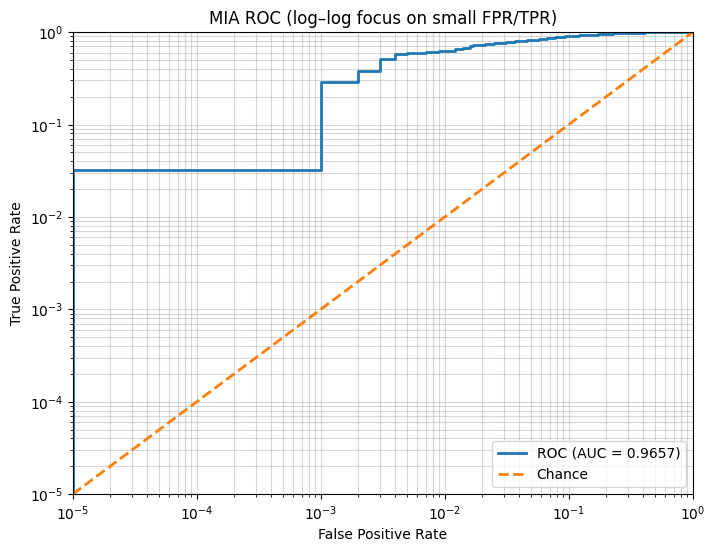

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

eps = 1e-12
fpr_ = np.clip(fpr, 1e-5, 1)
tpr_ = np.clip(tpr, 1e-5, 1)

fig, ax = plt.subplots(figsize=(8, 6))

ax.plot(fpr_, tpr_, lw=2, label=f'ROC (AUC = {auc_score:.4f})')
ax.plot([1e-5, 1], [1e-5, 1], lw=2, ls='--', label='Chance')

ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlim(1e-5, 1.0)
ax.set_ylim(1e-5, 1.0)

ticks = [1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1]
ax.set_xticks(ticks)
ax.set_yticks(ticks)
ax.get_xaxis().set_minor_formatter(plt.NullFormatter())
ax.get_yaxis().set_minor_formatter(plt.NullFormatter())

ax.set_xlabel('False Positive Rate')
ax.set_ylabel('True Positive Rate')
ax.set_title('MIA ROC (log–log focus on small FPR/TPR)')
ax.legend(loc='lower right')
ax.grid(True, which='both', alpha=0.5)

plt.show()

3.0647540429257623


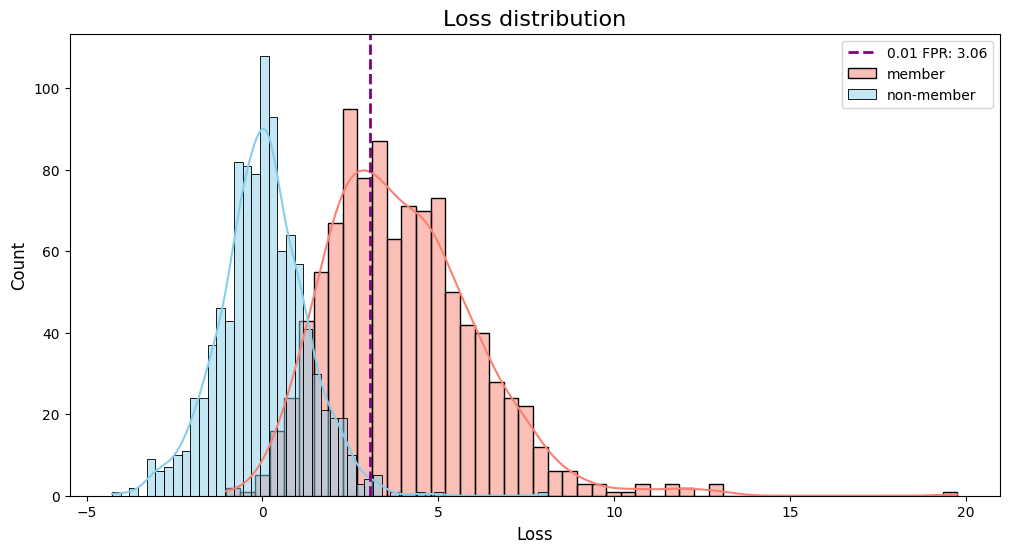

In [ ]:
# draw distribution
import matplotlib.pyplot as plt
import seaborn as sns

# y_true = np.array(label_items)
# scores = np.array(scores_test)

scores_mem = scores[y_true == 1]
scores_non = scores[y_true == 0]

plt.figure(figsize=(12, 6))
sns.histplot(scores_mem, bins=50, color='salmon', kde=True, label='member')
sns.histplot(scores_non, bins=50, color='skyblue', kde=True, label='non-member')

threshold_value = np.percentile(scores_non, q=99)
print(threshold_value)
plt.axvline(
    x=threshold_value,
    color='purple',
    linestyle='--',
    linewidth=2,
    label=f'0.01 FPR: {threshold_value:.2f}'
)


plt.title('Loss distribution', fontsize=16)
plt.xlabel('Loss', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.legend(fontsize=10)

plt.show()

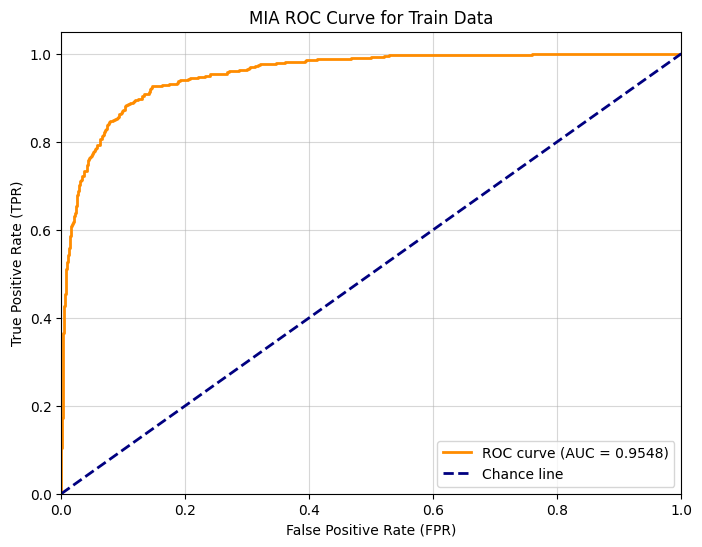

In [ ]:
# draw ROC curve and attach the figure in the report
plt.figure(figsize=(8, 6))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'ROC curve (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--', label='Chance line')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (FPR)')
plt.ylabel('True Positive Rate (TPR)')
plt.title(f'MIA ROC Curve for Train Data')
plt.legend(loc="lower right")
plt.grid(alpha=0.5)
plt.show()